# FX sources, timing and historical data

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Production acquisition
Acquisition is opt-in and verifies pinned source bytes or saves a dated source receipt. Defaults preserve cached files. The analysis below is retrospective documentation executed after the study was frozen; its exploratory summaries were not used to tune a new model.

In [2]:
RUN_FETCH = False
if RUN_FETCH:
    from src.data.multi_asset import fetch_snapshot
    destination = Path('data/external/multi-asset-v1/development')
    assert not destination.exists(), 'Preserve historical snapshot; use a fresh checkout'
    _, receipt = fetch_snapshot(destination,'2017-01-01','2025-12-31')
    print('Acquired snapshot SHA256:', receipt['sha256'])
print('Acquisition opt-in enabled:', RUN_FETCH)


Acquisition opt-in enabled: False


## Bank of Canada historical development snapshot
The snapshot is real public reference FX data, not executable quotes. Only aggregate distribution plots leave ignored data. This notebook reads development through 2025; it never fetches or tunes against 2026. Current API data are not historical publication-vintage reconstructions.

In [3]:
source = Path('data/external/multi-asset-v1/development/panel.csv')
raw = source.read_bytes()
panel = pd.read_csv(source)
panel['date'] = pd.to_datetime(panel.date,utc=True)
assets = [column for column in panel if column!='date']
returns = np.log(panel[assets]).diff()
print('Snapshot SHA256:',hashlib.sha256(raw).hexdigest())
print('Rows:',len(panel),'dates:',panel.date.min(),panel.date.max())
print('Monotonic:',panel.date.is_monotonic_increasing,'duplicate dates:',panel.date.duplicated().sum())
display(returns.describe(percentiles=[.01,.05,.5,.95,.99]).T)

Snapshot SHA256: 0070370cf34a930ad935979f13554d00b0a61143581fc22882ef16fe11f76b1a
Rows: 2244 dates: 2017-01-03 00:00:00+00:00 2025-12-31 00:00:00+00:00
Monotonic: True duplicate dates: 0


,count,mean,std,min,1%,5%,50%,95%,99%,max
FXEURCAD,2243.0,0.000063,0.003866,-0.014766,-0.009545,-0.006137,0.000000,0.006322,0.010520,0.024199
FXGBPCAD,2243.0,0.000050,0.004456,-0.023234,-0.011249,-0.007081,0.000058,0.007018,0.012411,0.024608
FXAUDCAD,2243.0,-0.000026,0.004036,-0.037736,-0.010134,-0.006702,0.000000,0.006235,0.010401,0.021101


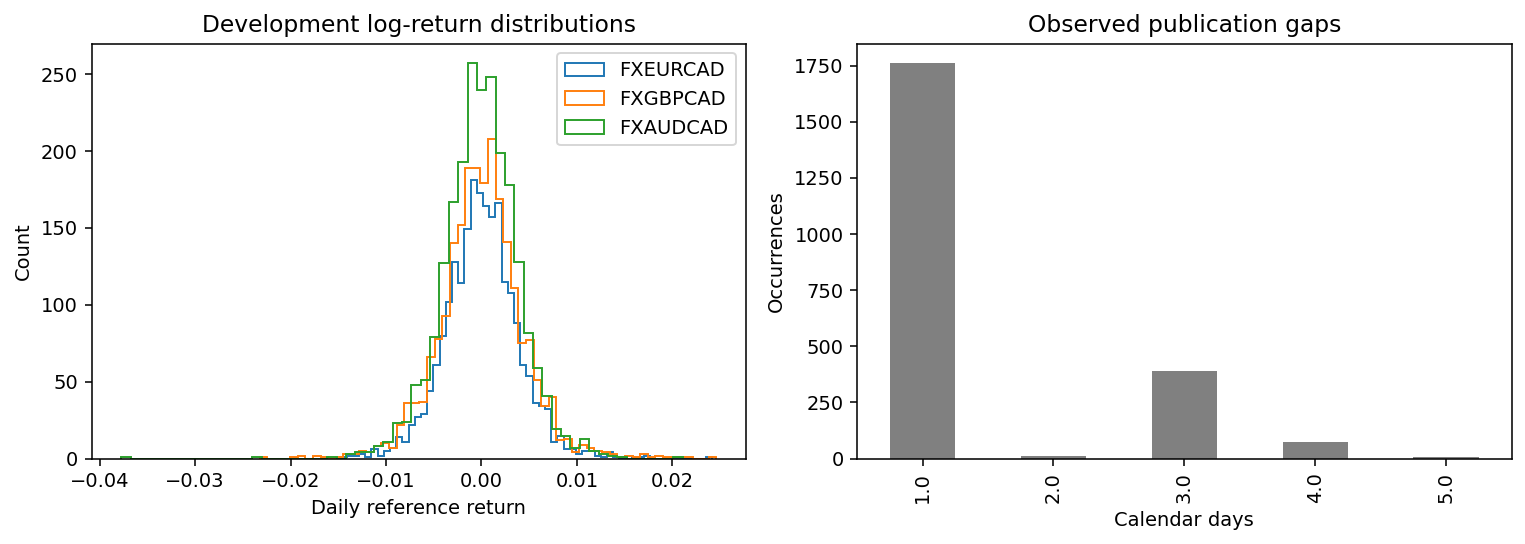

In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for asset in assets:
    axes[0].hist(returns[asset].dropna(),bins=60,histtype='step',label=asset)
axes[0].set(title='Development log-return distributions',xlabel='Daily reference return',ylabel='Count')
axes[0].legend()
gaps = panel.date.diff().dt.days.dropna().value_counts().sort_index()
gaps.plot.bar(ax=axes[1],color='gray')
axes[1].set(title='Observed publication gaps',xlabel='Calendar days',ylabel='Occurrences')
show_figure(fig,'quant_development_distributions')

## Timing contract and chronological folds
Features use published observations through the decision date. Labels are delayed t+1→t+2 returns; training purges labels crossing the boundary. Mean training ends in 2024, 2025 calibrates residual intervals, and 2026 was released previously. Peer features are lagged and EWMA requires full causal prefix context.

In [5]:
plan=read_json('docs/uncertainty-plan.json')
display(pd.DataFrame([{'role':'model validation','years':str(plan['validation_years'])},{'role':'calibration','years':str(plan['calibration_year'])},{'role':'observed test','years':str(plan['test_year'])}]))
provenance=read_json('models/uncertainty-v2/selection.json')['development_provenance']
print('Source provenance:',provenance)

,role,years
0,model validation,"[2021, 2022, 2023, 2024]"
1,calibration,2025
2,observed test,2026


Source provenance: {'url': 'https://www.bankofcanada.ca/valet/observations/FXEURCAD,FXGBPCAD,FXAUDCAD/json?start_date=2017-01-01&end_date=2025-12-31', 'sha256': '58c8d02de064898f4387d5727972083d5ea3850aa94009da200f07fbad97df5e', 'assets': ['FXEURCAD', 'FXGBPCAD', 'FXAUDCAD'], 'rows': 2244, 'first': '2017-01-03 00:00:00+00:00', 'last': '2025-12-31 00:00:00+00:00', 'retrieved_at_utc': '2026-10-15T20:09:46.213010+00:00', 'source': 'Bank of Canada, Valet API; no endorsement', 'terms': 'https://www.bankofcanada.ca/terms/', 'vintage_limitation': 'Current API snapshot, not historical as-published vintages'}
